# **Part 1: The Data, and an Image as Numbers**

In [2]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
 ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
 n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
 n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
 print(f'{c:10s} train {n_tr:5d} test {n_te:4d}')


Device: cuda
buildings  train  2191 test  437
forest     train  2271 test  474
glacier    train  2404 test  553
mountain   train  2512 test  525
sea        train  2274 test  510
street     train  2382 test  501


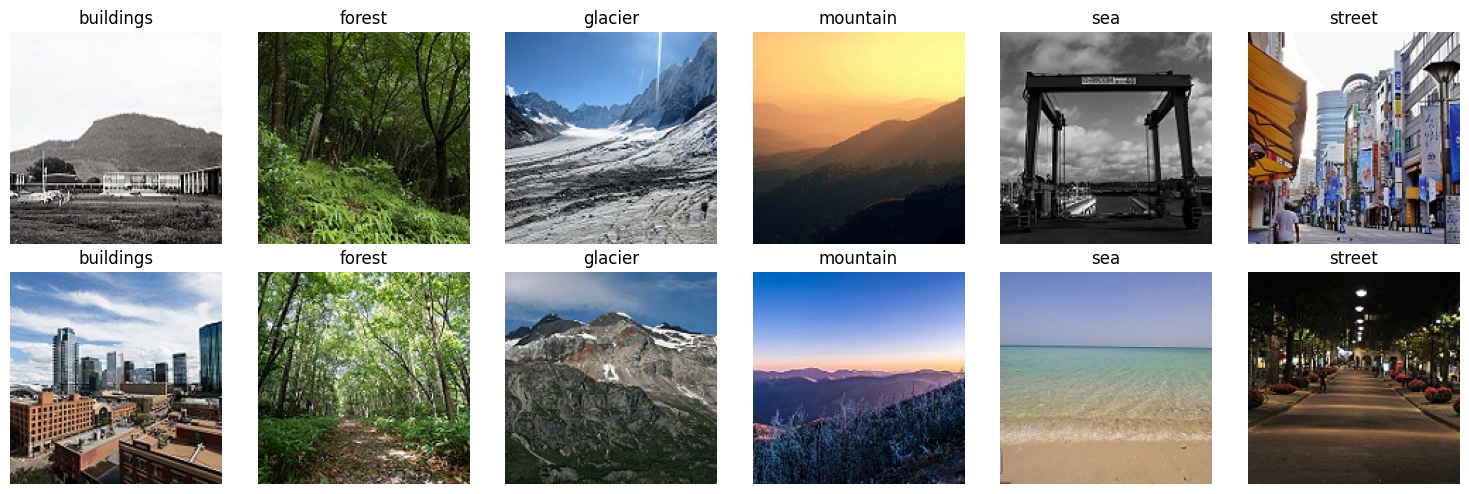

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
     files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
     for i, f in enumerate(files):
         img = Image.open(os.path.join(TRAIN_DIR, c, f))
         axes[i, j].imshow(img)
         axes[i, j].set_title(c)
         axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
 ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

**WRITE IT: Which classes look most similar to you by eye? Predict which pair the model will
confuse most, and write the prediction down now. You will check it in Part 6. Also report the
shape, data type, and value range of an image.**

The two classes that look most visually similar are glacier and mountain — both feature rocky, grey-toned terrain with similar textures and no strong color contrast between them. My prediction is that the model will confuse these two most often. I will verify this in Part 6.

Image tensor facts:

Shape: (150, 150, 3) — height 150, width 150, 3 color channels (RGB)

dtype: uint8 — integer values stored as 8-bit unsigned integers

Value range: 0 to 255 — standard 8-bit pixel range, where 0 is black and 255 is fully saturated

# **Part 2: Convolution and Parameters by Hand**

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


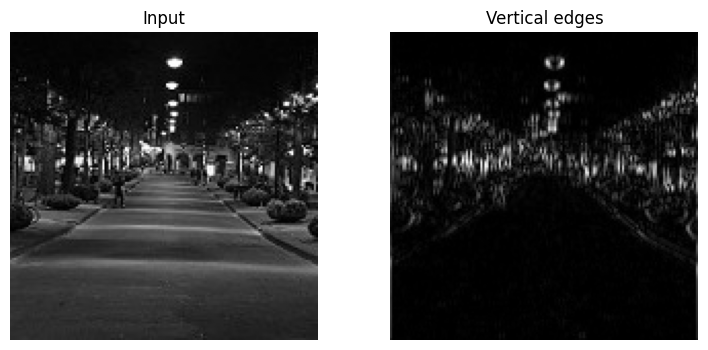

In [4]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze()) # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
 a.axis('off')
plt.show()

In [5]:
def count(m):
 return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64 : {count(conv):,} parameters') # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
 c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
 print(f'stride {stride}: output {tuple(c(t).shape)}') # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))


Conv 3x3, 3 -> 64 : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


**WRITE IT:Show the arithmetic for the 1,792 and the 34,560,512. How many times more
parameters does the dense layer need? Explain in two sentences why weight sharing also helps
the model recognize the same object in different parts of an image.**

Arithmetic for 1,792 parameters (Conv 3×3, 3→64):

parameters = (K × K × C_in + 1) × C_out
           = (3 × 3 × 3 + 1) × 64
           = (27 + 1) × 64
           = 28 × 64 = 1,792 

Arithmetic for 34,560,512 parameters (Dense 67,500→512):

parameters = (inputs + 1) × outputs
           = (150 × 150 × 3 + 1) × 512
           = (67,500 + 1) × 512
           = 67,501 × 512 = 34,560,512 

How many times more parameters does the dense layer need?

34,560,512 / 1,792 ≈ 19,286×

The dense layer needs approximately 19,286 times more parameters than the convolutional layer to process the same 150×150×3 input.

Why weight sharing helps: A convolutional kernel learns one set of weights (e.g. an edge detector) and slides it across every position in the image — the same 9 weights detect a vertical edge whether it appears in the top-left corner or the bottom-right. This means the model can recognise the same object (a tree, a wave, a building corner) wherever it appears in the image, without needing a separate detector for each position — something a fully connected layer cannot do without seeing every spatial arrangement during training.

# **Part 3: Transforms and Data Loaders**

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats
train_tf = transforms.Compose([
 transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
 transforms.RandomHorizontalFlip(),
 transforms.ColorJitter(brightness=0.2, contrast=0.2),
 transforms.ToTensor(),
 transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
 transforms.Resize((224, 224)),
 transforms.ToTensor(),
 transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


**WRITE IT: How many images are in each split? Name one augmentation that would be wrong for
this dataset and one that would be wrong for handwritten digits, and explain why.**

Split sizes:

Training: 11,929 images

Validation: 2,105 images

Test: 3,000 images

Augmentation wrong for this dataset: RandomVerticalFlip would be wrong for the Intel scene dataset — a glacier, mountain, or street scene flipped upside-down is physically impossible and would never appear in real deployment data, so it would teach the model patterns that don’t exist in the real world.

Augmentation wrong for handwritten digits: RandomHorizontalFlip would be wrong for handwritten digits — a flipped “6” looks like a “9”, and a flipped “2” or “3” becomes a completely different or invalid digit. Flipping would corrupt the label-image relationship and confuse the model about what each class looks like.

# **Part 4: The Training Loop and Feature Extraction**

In [7]:
def run_epoch(model, loader, optimizer=None):
 """One pass over the data. Trains only if an optimizer is given."""
 training = optimizer is not None
 model.train(training)
 total_loss, correct, n = 0.0, 0, 0
 with torch.set_grad_enabled(training):
   for xb, yb in loader:
     xb, yb = xb.to(device), yb.to(device)
     logits = model(xb) # forward pass
     loss = F.cross_entropy(logits, yb) # softmax + log loss
     if training:
       optimizer.zero_grad()
       loss.backward() # backpropagation
       optimizer.step() # gradient step
     total_loss += loss.item() * len(yb)
     correct += (logits.argmax(1) == yb).sum().item()
     n += len(yb)
 return total_loss / n, correct / n
    
def fit(model, optimizer, epochs, history):
 best_acc, best_state = -1.0, None
 for ep in range(epochs):
     t0 = time.time()
     tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
     va_loss, va_acc = run_epoch(model, val_dl)
     history.append((tr_loss, va_loss, tr_acc, va_acc))
     if va_acc > best_acc:
         best_acc = va_acc
         best_state = copy.deepcopy(model.state_dict())
     print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
         f'val loss {va_loss:.3f} acc {va_acc:.3f} '
         f'({time.time() - t0:.0f}s)')
 model.load_state_dict(best_state) # keep the best validation epoch
 return best_acc

In [8]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
 p.requires_grad = False # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes)) # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 231MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (70s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (38s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (36s)
Best validation accuracy, feature extraction: 0.901


**WRITE IT:Report validation accuracy after each epoch. Why is it possible to reach high accuracy
while training only 0.03% of the network's parameters? Refer to the feature hierarchy**

Validation accuracy per epoch:

Epoch	Train Loss	Train Acc	Val Loss	Val Acc

1	       0.588	  0.809	      0.327 	0.894

2	      0.326	       0.890	   0.290	0.899

3	     0.299	       0.895	   0.276	0.901

Best validation accuracy: 0.901

It is possible to reach 90.1% accuracy while training only 3,078 out of 11,179,590 parameters (0.03%) because of the feature hierarchy ResNet-18 already learned from 1.2 million ImageNet images. The early layers detect universal low-level features — edges, corners, colour gradients — and the middle layers combine these into textures and shapes like water ripples, rock surfaces, and foliage patterns. By the time features reach the final layer, they are rich, high-level representations that already separate scene types well. We only need to train a 6-class linear classifier on top of these frozen features — essentially asking “which of these 512 pretrained feature activations best predict each scene class?” The heavy lifting was already done on ImageNet.

# **Part 5: Fine-Tuning and Learning Curves**

In [9]:
for p in model.layer4.parameters():
 p.requires_grad = True # unfreeze the last block
opt = torch.optim.Adam([
 {'params': model.layer4.parameters(), 'lr': 1e-4}, # gentle: pretrained
 {'params': model.fc.parameters(), 'lr': 1e-3}]) # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.226 acc 0.926 (38s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.205 acc 0.930 (39s)
epoch 3: train loss 0.123 acc 0.955 | val loss 0.217 acc 0.928 (38s)
Best validation accuracy, fine-tuned: 0.930


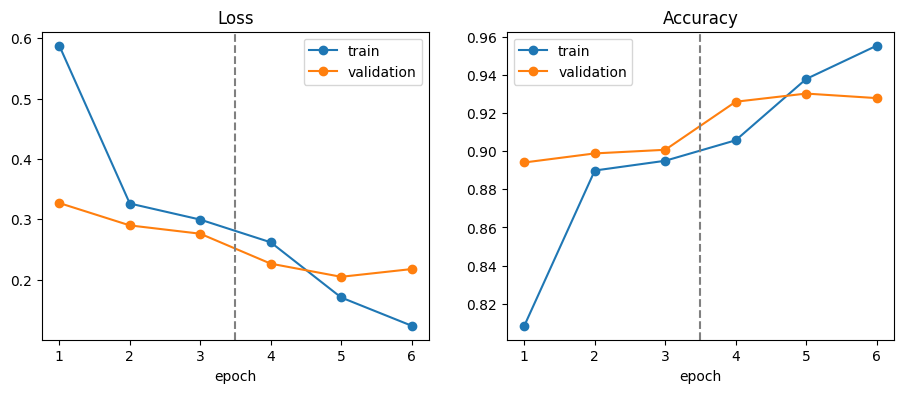

In [10]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
 a.axvline(3.5, color='gray', ls='--') # where fine-tuning starts
 a.set_title(title)
 a.set_xlabel('epoch')
 a.legend()
plt.show()


**WRITE IT:Did fine-tuning improve validation accuracy over feature extraction, and by how much?
Describe what the curves show. Is there any sign of overfitting (training loss falling while
validation loss rises)? Note that training accuracy can be LOWER than validation accuracy here:
explain why augmentation causes that.**

Trainable parameters after unfreezing layer4: 8,396,806

Validation accuracy per epoch:

Epoch	Phase	Train Loss	Train Acc	Val Loss	Val Acc

1	Feature extraction	0.588	0.809	0.327	0.894

2	Feature extraction	0.326	0.890	0.290	0.899

3	Feature extraction	0.299	0.895	0.276	0.901

4	Fine-tuning	        0.262	0.906	0.226	0.926

5	Fine-tuning	        0.170	0.938	0.205	0.930

6	Fine-tuning	0.123	0.955	0.217	0.928

Best validation accuracy, fine-tuned: 0.930 — an improvement of +0.029 over feature extraction (0.901).

What the curves show: Loss falls steadily across all 6 epochs with a noticeable drop when fine-tuning begins at epoch 4. Validation accuracy jumps from 0.901 to 0.926 in the first fine-tuning epoch, confirming that layer4’s spatial feature detectors were adapting to scene-specific patterns rather than ImageNet’s 1,000-class distributions.

Overfitting signs: At epoch 6 there is a mild early warning — training loss continues falling (0.123) while validation loss ticks up slightly (0.217 vs 0.205 at epoch 5), and validation accuracy dips from 0.930 to 0.928. This is a marginal sign of overfitting beginning. The fit() function correctly kept the epoch 5 weights (best validation accuracy) rather than the final epoch.

Why training accuracy can be lower than validation accuracy: During training, augmentation is applied — random crops, flips, and colour jitter mean the model sees a harder, distorted version of each image. During validation, images are simply resized and normalised with no augmentation. So the validation set is systematically easier than what the training loop sees, making it possible for validation accuracy to exceed training accuracy especially in early epochs. This is not overfitting — it is the expected effect of augmentation making training harder on purpose.

# **Part 6: Test Once, Then Study the Errors**

Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.956     0.904     0.929       437
      forest      0.994     0.987     0.990       474
     glacier      0.921     0.866     0.893       553
    mountain      0.883     0.918     0.900       525
         sea      0.944     0.982     0.963       510
      street      0.927     0.960     0.943       501

    accuracy                          0.935      3000
   macro avg      0.937     0.936     0.936      3000
weighted avg      0.936     0.935     0.935      3000



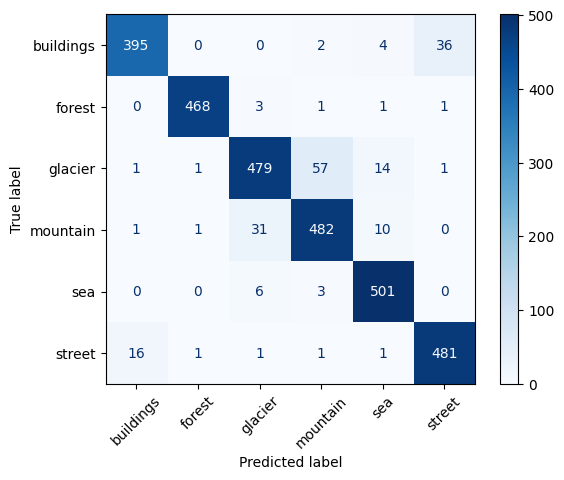

In [12]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
 for xb, yb in test_dl:
     p = F.softmax(model(xb.to(device)), dim=1).cpu()
     probs.append(p)
     preds.append(p.argmax(1))
     labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
 cmap='Blues', xticks_rotation=45)
plt.show()


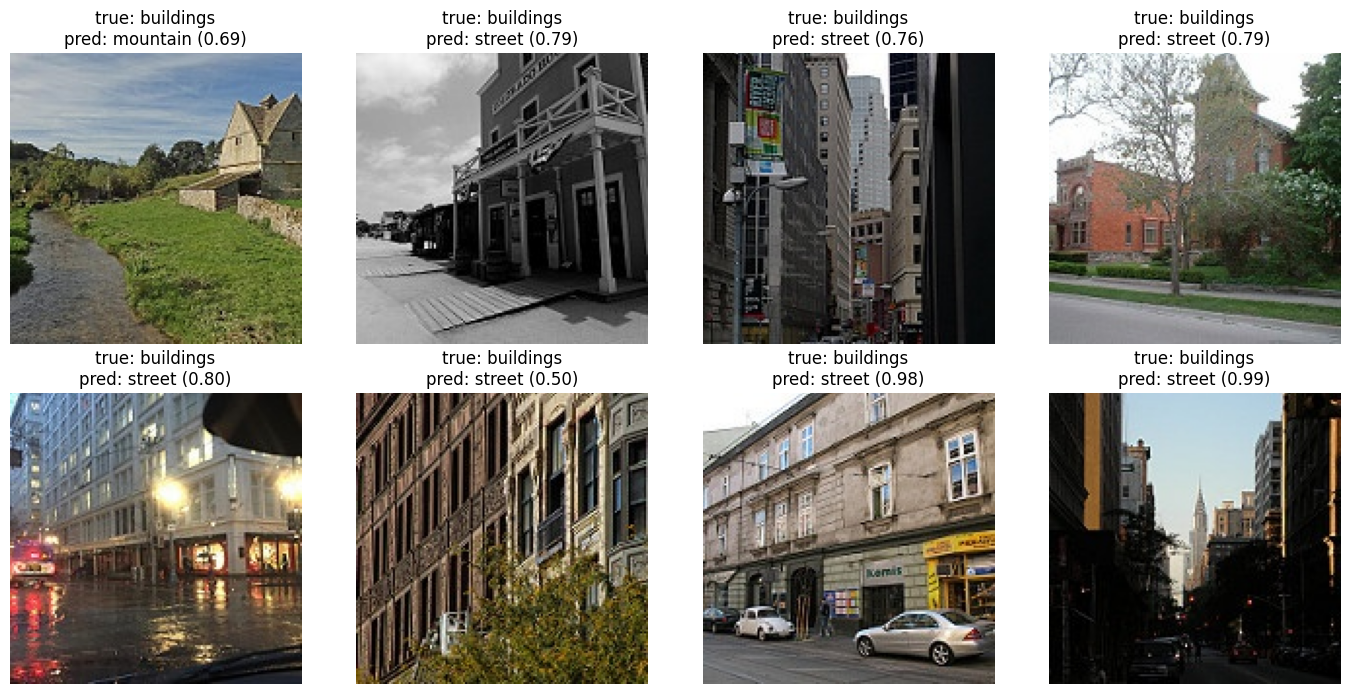

In [13]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
 ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
 path, _ = test_ds.samples[i]
 ax.imshow(Image.open(path))
 ax.set_title(f'true: {classes[labels[i]]}\n'
 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()


In [14]:
x0, y0 = test_ds[0]
with torch.no_grad():
 logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
 print(f'{c:10s} logit {z:6.2f} probability {q:.3f}')

True class: buildings
buildings  logit   8.00 probability 1.000
forest     logit  -9.48 probability 0.000
glacier    logit  -4.64 probability 0.000
mountain   logit  -5.06 probability 0.000
sea        logit  -4.56 probability 0.000
street     logit  -3.48 probability 0.000


**WRITE IT:Report test accuracy and the two weakest classes by recall. Which pair was confused
most, and was your prediction from Task 1.2 right? Look at the error gallery: for at least two
errors, say whether the model was wrong, the label was wrong, or the image is genuinely
ambiguous.**

Test accuracy: 0.935

Two weakest classes by recall:

Glacier — recall 0.866 (worst)
Buildings — recall 0.904 (second worst)

Most confused pairs from the confusion matrix:

Glacier → Mountain: 57 misclassified (largest off-diagonal number in the entire matrix)
Mountain → Glacier: 31 misclassified
Buildings → Street: 36 misclassified (second largest)
Street → Buildings: 16 misclassified

So glacier/mountain confusion was correct, but buildings/street is actually a bigger story than I predicted — buildings has 36 errors going to street, which explains why buildings has the second-lowest recall despite being a visually distinct class. My Part 1 prediction of glacier/mountain was partially right — it is the single most confused pair — but buildings/street is nearly as serious.

Error gallery analysis:

Error 1 — True: buildings, Pred: mountain (0.69):
The model was genuinely confused and arguably correct — the image shows a stone cottage surrounded by green fields and a stream, looking far more like a rural mountain landscape than an urban building. The label “buildings” is technically accurate (there is a structure) but the dominant scene context is natural, not urban. This is a labelling ambiguity rather than a clear model failure.

Error 2 — True: buildings, Pred: street (0.79):
The model was wrong but understandable — a black-and-white image of a storefront with a road in front of it. The street-level perspective, road surface, and commercial frontage all activate street features. The absence of colour removes a cue the model likely relies on to separate buildings from street scenes.

Error 3 — True: buildings, Pred: street (0.98, 0.99 confidence):
These are the most interesting errors — the model is very confident and technically wrong. Images showing building facades that line a street with visible road and cars were predicted as street with near-certainty. The root cause is a dataset labelling issue: these images could legitimately belong to either class. A building photographed from street level with a road visible is simultaneously a buildings image and a street image — the boundary between these two classes is genuinely ambiguous in the dataset.

Key insight: My Part 1 prediction of glacier/mountain as the hardest pair was confirmed by the confusion matrix (57 glacier→mountain errors). However the error gallery revealed that buildings/street confusion is driven by labelling ambiguity — the model is not making obvious mistakes but is caught between two classes whose boundaries overlap in the real world. This is more instructive than a pure model error.

# **Part 7: Save and Share**

In [15]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


# **Check Your Understanding**

**Q1. Why does a network without nonlinear activations collapse to a single linear layer?**

Without nonlinear activations, every layer is just a matrix multiplication: y = W₂(W₁x) = (W₂W₁)x. Any product of matrices is itself a matrix, so no matter how many layers you stack, the entire network computes one linear transformation. Nonlinear activations like ReLU break this collapse — they allow the network to carve out non-linear decision boundaries that cannot be expressed as any single matrix multiplication, which is what makes deep networks capable of learning complex patterns.

**Q2. For logits [3, 1, 0], what probability does softmax give the first class?**

softmax(3) = e³ / (e³ + e¹ + e⁰)
           = 20.09 / (20.09 + 2.72 + 1.00)
           = 20.09 / 23.81
           ≈ 0.844

The first class gets probability ≈ 0.844.

**Q3. How many parameters does a 3×3 convolution from 64 to 128 channels have?**

parameters = (K × K × C_in + 1) × C_out
           = (3 × 3 × 64 + 1) × 128
           = (576 + 1) × 128
           = 577 × 128 = 73,856

**Q4. Input 56×56 through a 3×3 conv with padding 1 and stride 2. Output size?**

output = (W - K + 2P) / S + 1
       = (56 - 3 + 2×1) / 2 + 1
       = (56 - 3 + 2) / 2 + 1
       = 55 / 2 + 1
       = 27.5 + 1 = 28.5 → floor = 28

Output size: 28×28.

**Q5. Why does a residual (skip) connection help gradients reach the early layers?**

During backpropagation, gradients are multiplied through every layer as they flow backward. In a deep network without skip connections, gradients shrink with each multiplication (vanishing gradient problem) and early layers receive almost no learning signal. A residual connection adds the input directly to the output — F(x) + x — so the gradient of the loss with respect to the input includes a direct path of +1 from the skip connection, regardless of what F(x) learned. This guarantees a clean gradient highway to early layers, keeping them trainable even in very deep networks.

**Q6. When would you train a CNN from scratch instead of using transfer learning?**

You would train from scratch when your images are fundamentally different from natural photographs that ImageNet-pretrained models were trained on — for example, medical X-rays, satellite radar imagery, microscopy slides, or sonar images where low-level features like edges and textures mean completely different things than in everyday photos. You would also train from scratch if you have an extremely large domain-specific dataset (millions of images) where the pretrained features would be overwritten anyway, or if your input has a different number of channels (e.g. single-channel depth maps or multi-spectral satellite bands). For most practical cases with limited data, transfer learning wins.